# Delhi NCR AQI — walk-forward forecasting, 1 to 10 days ahead (v9)

### Goals
1. Explore the engineered daily station-level dataset (station history, ERA5 surface and upper air, CAMS aerosol, FIRMS fires).
2. Forecast daily AQI 1 to 10 days ahead for each station, and PM2.5, ozone (daily mean and 8-hour maximum) and NOx.
3. Compare, on identical evaluation rows: persistence and weekly-seasonal-naive baselines, SARIMAX, Ridge, Random Forest, LightGBM and XGBoost (direct multi-horizon).
4. Show what each data family adds (feature-family ablation) and how accuracy differs in the stubble season, winter and the rest of the year.
5. Explain the tree models with SHAP, grouped by the families in `feature_groups.json`.
6. Produce a 10-day forecast with uncertainty bands from the latest data.

> **Modelling rule:** every feature used to predict day `t+h` is known at the end of day `t`. `build_features.py` enforces it and runs a future-leakage test on station and external data. Calendar facts about day `t+h` (weekday, Diwali) are known in advance and are added per horizon in this notebook as `tgt_*` columns.

> **Scope:** this is a data-driven forecasting system that uses reanalysis meteorology and CAMS aerosol as lagged inputs. It is not a coupled WRF-Chem simulation; the weather-pollution feedback is represented through proxies (inversion strength and persistence, boundary-layer depth, clearness index, diurnal temperature range, and met-chemistry interaction terms).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import spearmanr, loguniform, uniform
from scipy.optimize import nnls
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import ParameterSampler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
import shap

try:
    from lightgbm import LGBMRegressor
except ImportError as exc:
    raise ImportError("lightgbm is not installed. Install it with: pip install lightgbm") from exc

from build_features import diwali_offset, diwali_window, EXT_LAG_DAYS   # shared calendar helpers and the external-data lag

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

# ---------------- CONFIG ----------------
FEATURE_DIR = Path("features")           # written by build_features.py
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

FORECAST_HORIZON = 10
RETRAIN_EVERY = 30                       # days between retrains
WF_START = pd.Timestamp("2025-10-01")    # first day scored: the 2025 stubble season and early winter (~3 months, 4 origins).
                                         # Set to "2024-07-01" for the full 18-month evaluation (about 5x slower).
RANDOM_STATE = 42

RUN_SARIMAX = False                      # slow, and the weakest model in the full run; set True to include it
RUN_SECONDARY_TARGETS = True             # extra targets with XGBoost; the list is SECONDARY_TARGETS below
SECONDARY_TARGETS = ["PM25", "O3_8H"]    # add "O3" and "NOx" if you have the time
RUN_ABLATION = True                      # drop one feature family at a time, XGBoost, a few horizons
RUN_SHAP = True
ABLATION_HORIZONS = [1, 5, 10]
SHAP_HORIZONS = [1, 5]
SHAP_SAMPLE_SIZE = 800
SHAP_MODELS = ["XGBoost", "LightGBM"]    # Random Forest SHAP is slow; add "RandomForest" if wanted
HORIZONS = list(range(1, FORECAST_HORIZON + 1))

# Hyperparameter tuning (time-series cross-validation on data BEFORE WF_START only; results are cached)
RUN_TUNING = True
RETUNE = False                           # False: reuse outputs/best_params.json when it exists
TUNE_MODELS = ["LightGBM", "XGBoost", "RandomForest", "Ridge"]
TUNE_TRIALS = 10                         # random candidates per model and horizon, plus the current setting
TUNE_HORIZONS = [1, 5, 10]               # other horizons use the nearest tuned one
TUNE_FOLDS = 4
TUNE_FOLD_DAYS = 90

# Weather-feature forecasting with a Random Forest, and the two-stage test
RUN_WEATHER_MODEL = True
RUN_STAGE2 = True                        # does predicted weather help the AQI model?
STAGE2_HORIZONS = [3, 5, 10]

## 1. Load the daily dataset

`build_features.py` writes the daily table, the feature list, the feature-to-family map and the target definitions. The notebook reads all four, so a new feature added in the builder is picked up here without editing any prefix list.

In [2]:
daily = (pd.read_csv(FEATURE_DIR / "daily_features.csv", parse_dates=["date"])
           .sort_values(["station", "date"]).reset_index(drop=True))
GROUPS = json.loads((FEATURE_DIR / "feature_groups.json").read_text())
TARGETS = json.loads((FEATURE_DIR / "targets.json").read_text())
BASE_FEATURES = [c.strip() for c in (FEATURE_DIR / "feature_list.txt").read_text().splitlines() if c.strip()]
BASE_FEATURES = [c for c in BASE_FEATURES if c in daily.columns]

daily["AQI"] = daily["d_AQI"]

# Checks: one row per station-day, a complete calendar per station, targets present, no target used as a feature.
assert not daily.duplicated(["station", "date"]).any()
assert (daily.groupby("station")["date"].diff().dropna() == pd.Timedelta(days=1)).all(), "calendar has gaps"
for name, spec in TARGETS.items():
    missing = [f"{spec['prefix']}{h}" for h in HORIZONS if f"{spec['prefix']}{h}" not in daily.columns]
    assert not missing, f"{name}: missing target columns {missing}"
assert not [c for c in BASE_FEATURES if c.startswith("target")]

print("Daily shape:", daily.shape)
print("Date range:", daily["date"].min().date(), "to", daily["date"].max().date())
print("Stations:", daily["station"].unique().tolist())
print("Features:", len(BASE_FEATURES))
display(pd.Series({c: GROUPS[c] for c in BASE_FEATURES}).value_counts().to_frame("n_features"))
display(daily.groupby("station")["AQI"].agg(["count", "mean", "min", "max"]).round(2))
display((daily[BASE_FEATURES].isna().mean() * 100).sort_values(ascending=False).head(15).round(1).to_frame("missing_%").T)

Daily shape: (7305, 269)
Date range: 2022-01-01 to 2025-12-31
Stations: ['Anand Vihar', 'Dwarka Sector 8', 'IMD Lodhi Road', 'ITO', 'Punjabi Bagh']
Features: 214


,n_features
Met surface (ERA5),52
Met upper air (ERA5),40
Stubble fires,32
Pollutant history,28
AQI history,17
Aerosol (CAMS),14
Pollutant current,11
Calendar,8
City state,6
Local weather,3


,count,mean,min,max
station,,,,
Anand Vihar,1366,272.92,43.99,500.00
Dwarka Sector 8,1443,229.13,23.30,500.00
IMD Lodhi Road,1381,173.86,22.12,483.47
ITO,1398,202.73,41.81,491.17
Punjabi Bagh,1429,226.03,35.58,500.00


,viirs_ti_lag2d,viirs_belt_count_lag2d,viirs_belt_frp_lag2d,viirs_belt_frp_lag1d,viirs_belt_frp_roll3d,viirs_ti_roll7d,viirs_belt_count_roll7d,viirs_ti_lag1d,viirs_belt_count_roll3d,viirs_count_lag1d,viirs_night_count_lag1d,viirs_near_count_lag1d,viirs_belt_count_lag1d,viirs_frp_lag1d,viirs_ti_roll3d
missing_%,51.2,51.2,51.2,51.1,51.1,51.1,51.1,51.1,51.1,51.1,51.1,51.1,51.1,51.1,51.1


## 2. Exploratory analysis

Station AQI, seasonality, and how the physical drivers (inversion, boundary layer, fires, aerosol dimming) relate to next-day AQI.

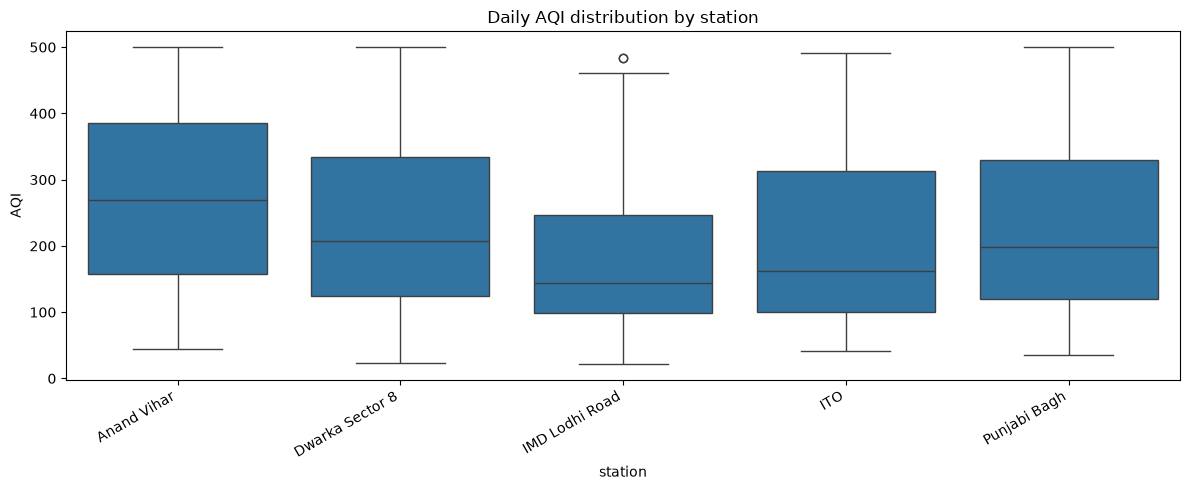

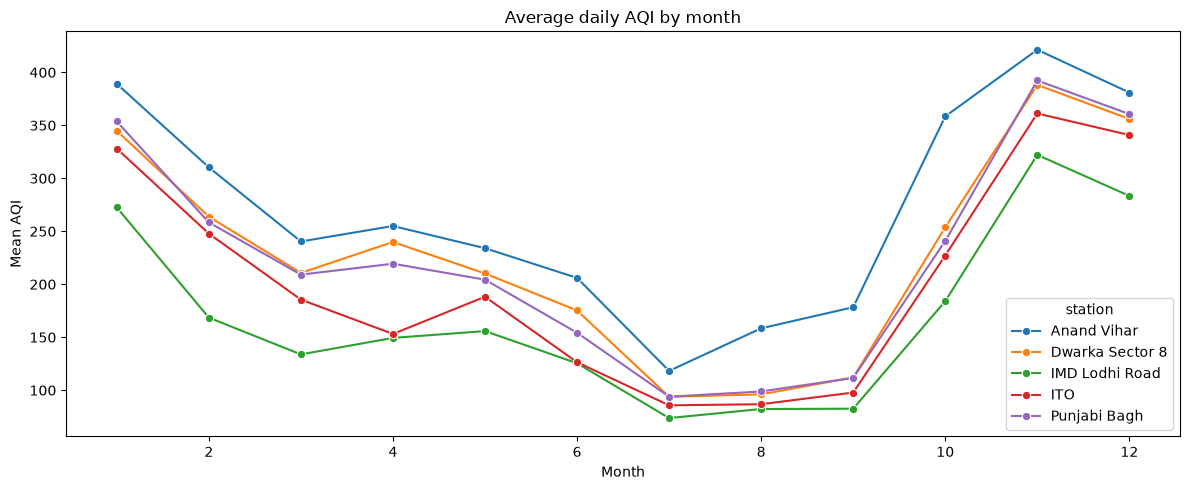

In [3]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=daily, x="station", y="AQI")
plt.xticks(rotation=30, ha="right")
plt.title("Daily AQI distribution by station")
plt.tight_layout()
plt.show()

monthly_profile = daily.groupby(["station", "month"])["AQI"].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_profile, x="month", y="AQI", hue="station", marker="o")
plt.title("Average daily AQI by month")
plt.xlabel("Month")
plt.ylabel("Mean AQI")
plt.tight_layout()
plt.show()

In [4]:
# Forecast-relevant correlation: each feature against the AQI one day ahead (Spearman, rows with both present).
def _spearman(col):
    m = daily[col].notna() & daily["target_h1"].notna()
    return spearmanr(daily.loc[m, col], daily.loc[m, "target_h1"]).correlation if m.sum() > 100 else np.nan

corr = pd.Series({c: _spearman(c) for c in BASE_FEATURES}).dropna()
corr_table = pd.DataFrame({"spearman_with_AQI_t+1": corr, "family": pd.Series(GROUPS)}).dropna()
corr_table["abs"] = corr_table["spearman_with_AQI_t+1"].abs()

print("Strongest single features overall:")
display(corr_table.sort_values("abs", ascending=False).head(15).drop(columns="abs").round(3))

print("Strongest physical / fire / aerosol drivers (not station history):")
phys = corr_table[~corr_table["family"].isin(["AQI history", "Pollutant history", "Pollutant current", "City state", "Calendar", "Local weather"])]
display(phys.sort_values("abs", ascending=False).head(20).drop(columns="abs").round(3))

Strongest single features overall:


,spearman_with_AQI_t+1,family
d_AQI,0.919,AQI history
d_PM25,0.916,Pollutant current
d_PM10,0.916,Pollutant current
AQI_roll_mean_3d,0.888,AQI history
d_PM25_roll_mean_3d,0.883,Pollutant history
d_PM10_roll_mean_3d,0.875,Pollutant history
city_PM25_today,0.871,City state
AQI_roll_mean_7d,0.862,AQI history
city_AQI_today,0.858,City state
d_PM25_roll_mean_7d,0.854,Pollutant history


Strongest physical / fire / aerosol drivers (not station history):


,spearman_with_AQI_t+1,family
inv_hours_frac_roll3d,0.704,Met surface (ERA5)
ua_r700_lag1d,-0.704,Met upper air (ERA5)
inv_hours_frac_lag1d,0.702,Met surface (ERA5)
cams_pm25_mean_roll3d,0.699,Aerosol (CAMS)
cams_pm10_mean_lag1d,0.692,Aerosol (CAMS)
cams_pm25_mean_lag1d,0.691,Aerosol (CAMS)
ua12_r800_lag1d,-0.690,Met upper air (ERA5)
inv_surface_mean_lag1d,0.679,Met surface (ERA5)
pressure_mean_roll3d,0.655,Met surface (ERA5)
pressure_mean_lag1d,0.646,Met surface (ERA5)


Mean next-day AQI by inv_hours_frac_lag1d quartile within each season


inv_quartile,Q1 low,Q2,Q3,Q4 high
season,,,,
Other,108.0,109.0,177.0,215.0
Stubble (Oct-Nov),230.0,330.0,359.0,349.0
Winter (Dec-Feb),279.0,290.0,318.0,352.0


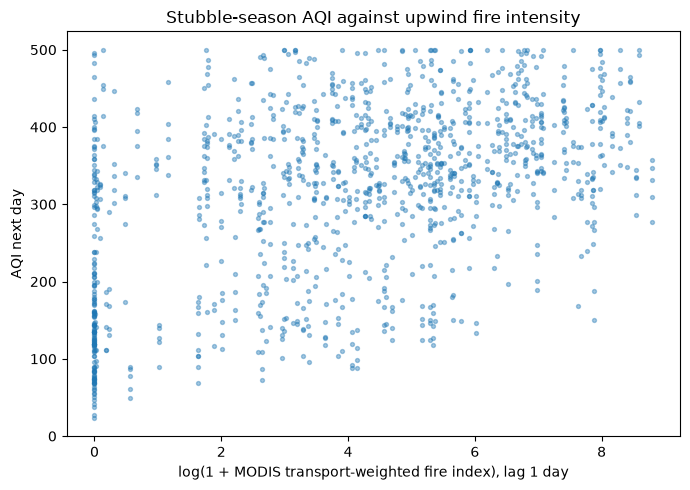

In [5]:
# Does the night-time inversion matter? Mean next-day AQI by inversion-hours quartile, split by season.
tmp = daily[["station", "date", "target_h1", "month"]].copy()
inv_col = [c for c in ["inv_hours_frac_lag1d", "inv_surface_night_lag1d"] if c in daily.columns][0]
tmp["inv"] = daily[inv_col]
tmp["season"] = np.where(tmp["month"].isin([10, 11]), "Stubble (Oct-Nov)",
                 np.where(tmp["month"].isin([12, 1, 2]), "Winter (Dec-Feb)", "Other"))
# rank first so ties (many zero-inversion days) cannot collapse the quartile edges
tmp["inv_quartile"] = tmp.groupby("season")["inv"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"]))
pivot = tmp.dropna(subset=["inv_quartile", "target_h1"]).pivot_table(
    index="season", columns="inv_quartile", values="target_h1", aggfunc="mean").round(0)
print("Mean next-day AQI by", inv_col, "quartile within each season")
display(pivot)

# Fires: next-day AQI against the transport-weighted fire index, October-November only.
if "modis_ti_lag1d" in daily.columns:
    sub = daily[daily["month"].isin([10, 11])].dropna(subset=["modis_ti_lag1d", "target_h1"])
    plt.figure(figsize=(7, 5))
    plt.scatter(np.log1p(sub["modis_ti_lag1d"].clip(lower=0)), sub["target_h1"], s=8, alpha=0.4)
    plt.xlabel("log(1 + MODIS transport-weighted fire index), lag 1 day")
    plt.ylabel("AQI next day")
    plt.title("Stubble-season AQI against upwind fire intensity")
    plt.tight_layout()
    plt.show()

## 3. Walk-forward set-up, evaluation helpers and baselines

Walk-forward origins start the day before `WF_START` and advance every `RETRAIN_EVERY` days. At origin `T` the model is trained only on rows whose label is known by `T` (row `t` is usable for horizon `h` only if `t + h <= T`) and then serves every day until the next origin. Each served row `t` forecasts `t + h`.

- **Persistence:** the last observed value (carried forward up to 3 days over a gap, so the baseline exists wherever the models do).
- **Weekly seasonal naive:** the last observed value on the same weekday as the target day.

In [6]:
cutoff = WF_START
EVAL_START = cutoff - pd.Timedelta(days=1)


def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[ok], y_pred[ok]
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred),
            "Bias": float(np.mean(y_pred - y_true))}


def metrics_by(df, by):
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for key, g in df.dropna(subset=["actual", "prediction"]).groupby(by):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({**dict(zip(by, key)), **evaluate(g["actual"], g["prediction"]), "n": len(g)})
    return pd.DataFrame(rows)


def last_observed(col):
    return daily.groupby("station")[col].transform(lambda s: s.ffill(limit=3))


def weekly_naive_lag(h):
    """Days back from origin t to the latest day with the same weekday as t+h: 7*ceil(h/7) - h."""
    return 7 * int(np.ceil(h / 7)) - h


def persistence_frame(actual_col, prefix, model_name, seasonal=False):
    last = last_observed(actual_col)
    frames = []
    for h in HORIZONS:
        tcol = f"{prefix}{h}"
        pred = last
        if seasonal:
            lag = weekly_naive_lag(h)
            pred = last if lag == 0 else last.groupby(daily["station"]).shift(lag)
        mask = (daily["date"] >= EVAL_START) & daily[tcol].notna() & pred.notna()
        f = daily.loc[mask, ["station", "date"]].copy()
        f["date"] = f["date"] + pd.Timedelta(days=h)          # target date
        f["horizon"] = h
        f["model"] = model_name
        f["actual"] = daily.loc[mask, tcol].to_numpy()
        f["prediction"] = pred[mask].to_numpy()
        frames.append(f)
    return pd.concat(frames, ignore_index=True)


baseline_rows = pd.concat([
    persistence_frame("d_AQI", "target_h", "Persistence"),
    persistence_frame("d_AQI", "target_h", "Weekly seasonal naive", seasonal=True),
], ignore_index=True)
baseline_results = metrics_by(baseline_rows, ["model", "horizon"])
display(baseline_results.pivot(index="horizon", columns="model", values="RMSE").round(1))

model,Persistence,Weekly seasonal naive
horizon,,
1,43.9,86.6
2,60.8,86.6
3,69.1,86.8
4,74.9,87.0
5,78.8,87.5
6,86.0,88.0
7,88.4,88.4
8,92.0,118.3
9,97.5,118.5


### 3.1 Feature matrix, target-day calendar and walk-forward engine

Direct forecasting: one model per horizon, `X(t) -> y(t+h)`. For horizon `h` the matrix also carries calendar facts about the target day (`tgt_*`: weekday, month, Diwali window), which are known in advance.

In [7]:
TGT_CAL_COLS = ["tgt_dayofweek", "tgt_is_weekend", "tgt_month", "tgt_doy_sin", "tgt_doy_cos",
                "tgt_diwali_window", "tgt_days_from_diwali"]
FEATURE_COLS = BASE_FEATURES + TGT_CAL_COLS
GROUPS.update({c: "Target-day calendar" for c in TGT_CAL_COLS})


def target_calendar(h):
    td = pd.DatetimeIndex(daily["date"]) + pd.Timedelta(days=h)
    return pd.DataFrame({
        "tgt_dayofweek": td.dayofweek,
        "tgt_is_weekend": (td.dayofweek >= 5).astype(int),
        "tgt_month": td.month,
        "tgt_doy_sin": np.sin(2 * np.pi * td.dayofyear / 365.25),
        "tgt_doy_cos": np.cos(2 * np.pi * td.dayofyear / 365.25),
        "tgt_diwali_window": diwali_window(td),
        "tgt_days_from_diwali": np.clip(diwali_offset(td), -15, 15),
    }, index=daily.index)


_X_cache = {}


def make_X(h):
    """Raw feature frame for horizon h: base features, station name, target-day calendar."""
    if h not in _X_cache:
        _X_cache[h] = pd.concat([daily[BASE_FEATURES + ["station"]], target_calendar(h)], axis=1)
    return _X_cache[h]


def make_prep(kind, num_cols):
    """passthrough: boosted trees (handle NaN natively). impute: median fill (random forest).
    impute_scale: median fill and standardise (ridge). Station is one-hot in every case."""
    cat = ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["station"])
    if kind == "passthrough":
        num = ("num", "passthrough", list(num_cols))
    elif kind == "impute":
        num = ("num", SimpleImputer(strategy="median", keep_empty_features=True), list(num_cols))
    elif kind == "impute_scale":
        num = ("num", Pipeline([("imp", SimpleImputer(strategy="median", keep_empty_features=True)),
                                ("sc", StandardScaler())]), list(num_cols))
    else:
        raise ValueError(kind)
    return ColumnTransformer([num, cat], remainder="drop")


def make_walk_forward_origins(dates, test_start, retrain_every=RETRAIN_EVERY):
    dates = pd.DatetimeIndex(pd.to_datetime(pd.Series(dates).dropna().unique())).sort_values()
    origin, max_date, out = pd.Timestamp(test_start) - pd.Timedelta(days=1), dates.max(), []
    while origin + pd.Timedelta(days=1) <= max_date:
        if origin in dates:
            out.append(origin)
        else:
            print("WARNING: origin not in the data, skipped:", origin.date())
        origin += pd.Timedelta(days=retrain_every)
    return pd.DatetimeIndex(out)


walk_forward_origins = make_walk_forward_origins(daily["date"], cutoff)
print("Walk-forward origins:", len(walk_forward_origins),
      "| first:", walk_forward_origins.min().date(), "| last:", walk_forward_origins.max().date())
print("Features per model:", len(FEATURE_COLS), "(including", len(TGT_CAL_COLS), "target-day calendar columns)")

Walk-forward origins: 4 | first: 2025-09-30 | last: 2025-12-29
Features per model: 221 (including 7 target-day calendar columns)


In [8]:
def walk_forward_direct_model(estimator, prep_kind, model_name, *, origins, target_prefix="target_h",
                              actual_col="d_AQI", horizons=None, num_cols=None, x_builder=None):
    """Walk-forward evaluation of a direct multi-horizon model.

    Retraining: once per origin and horizon, on rows with t + h <= origin only.
    Serving: the model fitted at origin T scores every row t in [T, next origin - 1] (or to the end
    of the data for the last origin), forecasting t + h. `days_since_retrain` records model age.
    """
    horizons = HORIZONS if horizons is None else list(horizons)
    num_cols = FEATURE_COLS if num_cols is None else list(num_cols)
    dates = daily["date"]
    actual_lookup = daily[["station", "date", actual_col]].rename(columns={actual_col: "actual"})
    origins_sorted = pd.DatetimeIndex(sorted(pd.to_datetime(list(origins))))
    max_date = dates.max()
    rows, log, last_pipes = [], [], {}

    for i, origin in enumerate(origins_sorted):
        serving_end = origins_sorted[i + 1] - pd.Timedelta(days=1) if i + 1 < len(origins_sorted) else max_date
        for h in horizons:
            target = f"{target_prefix}{h}"
            X_h = (x_builder or make_X)(h)
            train_m = (dates <= origin - pd.Timedelta(days=h)) & daily[target].notna()
            serve_m = (dates >= origin) & (dates <= serving_end)
            if train_m.sum() == 0 or serve_m.sum() == 0:
                continue

            est_h = estimator(h) if callable(estimator) else estimator     # a function h -> estimator allows per-horizon settings
            pipe = Pipeline([("prep", make_prep(prep_kind, num_cols)), ("model", clone(est_h))])
            pipe.fit(X_h.loc[train_m], daily.loc[train_m, target])
            pred = pipe.predict(X_h.loc[serve_m])

            served = daily.loc[serve_m, ["station", "date"]]
            fr = pd.DataFrame({
                "model": model_name,
                "station": served["station"].to_numpy(),
                "forecast_origin": origin,
                "date": (served["date"] + pd.Timedelta(days=h)).to_numpy(),      # target date
                "horizon": h,
                "days_since_retrain": (served["date"] - origin).dt.days.to_numpy(),
                "prediction": np.asarray(pred, dtype=float),
            }).merge(actual_lookup, on=["station", "date"], how="left")
            rows.append(fr[["model", "station", "forecast_origin", "date", "horizon",
                            "days_since_retrain", "actual", "prediction"]])
            last_pipes[h] = pipe
            log.append({"model": model_name, "forecast_origin": origin, "horizon": h,
                        "n_train": int(train_m.sum()), "n_days_served": int(serve_m.sum()),
                        "train_last_feature_date": dates[train_m].max()})

    pred_df = pd.concat(rows, ignore_index=True)
    metric_df = metrics_by(pred_df, ["horizon"])
    metric_df.insert(0, "model", model_name)
    return pred_df, metric_df, last_pipes, pd.DataFrame(log)


def fit_production(estimator, prep_kind, target_prefix, horizons=None):
    """Refit on every label known at the last date of the data, for the live forecast."""
    horizons = HORIZONS if horizons is None else list(horizons)
    as_of = daily["date"].max()
    pipes = {}
    for h in horizons:
        target = f"{target_prefix}{h}"
        m = (daily["date"] <= as_of - pd.Timedelta(days=h)) & daily[target].notna()
        est_h = estimator(h) if callable(estimator) else estimator
        pipe = Pipeline([("prep", make_prep(prep_kind, FEATURE_COLS)), ("model", clone(est_h))])
        pipe.fit(make_X(h).loc[m], daily.loc[m, target])
        pipes[h] = pipe
    return pipes


def predict_latest(pipes):
    """Forecast h days ahead of the last available day, for every station."""
    as_of = daily["date"].max()
    latest = daily[daily["date"] == as_of]
    out = []
    for h, pipe in pipes.items():
        t = latest[["station", "date"]].copy()
        t["horizon"] = h
        t["forecast_date"] = t["date"] + pd.Timedelta(days=h)
        t["prediction"] = pipe.predict(make_X(h).loc[latest.index])
        out.append(t)
    return pd.concat(out, ignore_index=True)

## 4. Machine-learning models, AQI target

Same origins, features and serving windows for every model, so the results are directly comparable. Ridge is linear and regularised on standardised inputs; with ~200 correlated features an unpenalised least-squares fit is unstable.

In [ ]:
XGB = XGBRegressor(n_estimators=700, max_depth=6, learning_rate=0.03, subsample=0.85, colsample_bytree=0.85,
                   objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1)

MODEL_CONFIGS = {
    "XGBoost": (XGB, "passthrough"),
    "LightGBM": (LGBMRegressor(n_estimators=700, num_leaves=63, learning_rate=0.03, subsample=0.85, subsample_freq=1,
                               colsample_bytree=0.85, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1), "passthrough"),
    "RandomForest": (RandomForestRegressor(n_estimators=400, max_depth=14, min_samples_leaf=2,
                                           random_state=RANDOM_STATE, n_jobs=-1), "impute"),
    "Ridge": (Ridge(alpha=30.0), "impute_scale"),
}

aqi_predictions, aqi_metrics, aqi_logs = {}, [], []
for name, (est, kind) in MODEL_CONFIGS.items():
    p, m, _, lg = walk_forward_direct_model(est, kind, name, origins=walk_forward_origins)
    aqi_predictions[name] = p
    aqi_metrics.append(m)
    aqi_logs.append(lg)
    print(f"Finished {name}: {len(p):,} predictions")

metrics_ml = pd.concat(aqi_metrics, ignore_index=True)
ml_training_log = pd.concat(aqi_logs, ignore_index=True)
display(ml_training_log.query("model == 'XGBoost'").head(10))

Finished XGBoost: 4,650 predictions
Finished LightGBM: 4,650 predictions


In [ ]:
all_results = pd.concat([baseline_results, metrics_ml], ignore_index=True)
display(all_results.pivot(index="horizon", columns="model", values="RMSE").round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=all_results, x="horizon", y="RMSE", hue="model", marker="o", ax=axes[0])
axes[0].set_title("RMSE by forecast horizon")
sns.lineplot(data=all_results, x="horizon", y="R2", hue="model", marker="o", ax=axes[1])
axes[1].set_title("R2 by forecast horizon")
for ax in axes:
    ax.set_xlabel("Days ahead")
    ax.set_xticks(HORIZONS)
plt.tight_layout()
plt.show() 

## 5. SARIMAX, station level

Same target, origins and serving windows as the ML models. Parameters are fitted at each origin; every served day re-conditions the model on everything observed up to that day with `fit.apply(...)`, so no future value is used. Set `RUN_SARIMAX = False` to skip this slow section.

In [ ]:
SARIMAX_ORDER = (1, 1, 1)
SARIMAX_SEASONAL_ORDER = (1, 1, 1, 7)


def walk_forward_sarimax(origins, order=SARIMAX_ORDER, seasonal_order=SARIMAX_SEASONAL_ORDER):
    origins_sorted = pd.DatetimeIndex(sorted(pd.to_datetime(list(origins))))
    max_date = daily["date"].max()
    rows, skipped = [], []
    for station, g in daily.groupby("station"):
        s = g.set_index("date")["d_AQI"].sort_index().asfreq("D")
        for i, origin in enumerate(origins_sorted):
            serving_end = origins_sorted[i + 1] - pd.Timedelta(days=1) if i + 1 < len(origins_sorted) else max_date
            train = s.loc[:origin].interpolate(method="time", limit_area="inside").dropna()
            if len(train) < max(20, seasonal_order[-1] * 3):
                skipped.append((station, origin.date()))
                continue
            fit = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            for t in s.loc[origin:serving_end].index:
                res_t = fit if t == origin else fit.apply(s.loc[:t])
                fc = np.asarray(res_t.get_forecast(steps=FORECAST_HORIZON).predicted_mean, dtype=float)
                for h in HORIZONS:
                    target_date = t + pd.Timedelta(days=h)
                    rows.append({"model": "SARIMAX", "station": station, "forecast_origin": origin,
                                 "date": target_date, "horizon": h, "days_since_retrain": (t - origin).days,
                                 "actual": s.get(target_date, np.nan), "prediction": fc[h - 1]})
    if skipped:
        print("SARIMAX origins skipped (too little history):", skipped[:5])
    return pd.DataFrame(rows)


if RUN_SARIMAX:
    sarimax_predictions = walk_forward_sarimax(walk_forward_origins)
    display(metrics_by(sarimax_predictions, ["horizon"]).round(2))
else:
    sarimax_predictions = pd.DataFrame(columns=["model", "station", "forecast_origin", "date", "horizon",
                                                "days_since_retrain", "actual", "prediction"])

## 6. Comparison on identical rows

Every model is scored on the same `(station, target date, horizon)` rows: the intersection of what all models produced with an observed actual. The coverage table shows any rows a model had outside that set.

In [ ]:
KEYS = ["station", "date", "horizon"]


def normalised(df):
    out = df[["model"] + KEYS + ["actual", "prediction"]].copy()
    out["station"] = out["station"].astype(str)
    out["date"] = pd.to_datetime(out["date"]).dt.normalize()
    out["horizon"] = out["horizon"].astype(int)
    return out.dropna(subset=["actual", "prediction"])


def common_rows(frames):
    """Stack the frames and keep only the rows every model has."""
    both = pd.concat([normalised(f) for f in frames if len(f)], ignore_index=True)
    key_sets = {m: set(map(tuple, g[KEYS].itertuples(index=False, name=None))) for m, g in both.groupby("model")}
    common = set.intersection(*key_sets.values())
    union = set.union(*key_sets.values())
    cov = pd.DataFrame({"scored_rows": {m: len(s) for m, s in key_sets.items()},
                        "rows_outside_common_set": {m: len(s - common) for m, s in key_sets.items()}})
    idx = pd.MultiIndex.from_tuples(sorted(common), names=KEYS)
    table = both.set_index(KEYS).join(pd.DataFrame(index=idx), how="inner").reset_index()
    return table, cov, len(common), len(union)


eval_table, coverage, n_common, n_union = common_rows(
    list(aqi_predictions.values()) + [sarimax_predictions, baseline_rows])
display(coverage)
print("Common evaluation rows:", n_common, "of", n_union, "in the union")
assert n_common > 0

equal_basis = metrics_by(eval_table, ["model", "horizon"])
display(equal_basis.pivot(index="horizon", columns="model", values="RMSE").round(1))
display(equal_basis.groupby("model")[["MAE", "RMSE", "R2"]].mean().sort_values("RMSE").round(2))

# Skill against persistence (1 = perfect, 0 = no better than persistence, negative = worse)
rm = equal_basis.pivot(index="horizon", columns="model", values="RMSE")
skill = 1 - rm.div(rm["Persistence"], axis=0)
display(skill.drop(columns="Persistence").round(3))

plt.figure(figsize=(11, 5))
sns.lineplot(data=equal_basis, x="horizon", y="RMSE", hue="model", marker="o")
plt.title("RMSE by horizon, identical rows for every model")
plt.xlabel("Days ahead")
plt.xticks(HORIZONS)
plt.tight_layout()
plt.show()

In [ ]:
# Where does the skill come from? Split the same rows by the season of the target day.
def season_of(dates):
    m = pd.to_datetime(dates).dt.month
    return np.select([m.isin([10, 11]), m.isin([12, 1, 2])], ["Stubble (Oct-Nov)", "Winter (Dec-Feb)"], "Other months")

eval_table["season"] = season_of(eval_table["date"])
by_season = metrics_by(eval_table[eval_table["horizon"].isin([1, 3, 5, 10])], ["season", "horizon", "model"])
for season, g in by_season.groupby("season"):
    print(season)
    display(g.pivot(index="model", columns="horizon", values="RMSE").round(1))

# Model age: does accuracy fall as the 30-day-old model gets older? (XGBoost, horizon 3)
x = aqi_predictions["XGBoost"].query("horizon == 3").copy()
x["age_bucket"] = pd.cut(x["days_since_retrain"], [-1, 7, 14, 21, 30], labels=["0-7", "8-14", "15-21", "22-30"])
display(metrics_by(x, ["age_bucket"])[["age_bucket", "RMSE", "MAE", "n"]].round(1))

In [ ]:
# Severe-episode skill: can the model flag days that cross a CPCB threshold?
def exceedance_scores(table, thresholds=(300, 400), horizons=(1, 3, 5, 10)):
    rows = []
    for (model, h), g in table[table["horizon"].isin(horizons)].groupby(["model", "horizon"]):
        for thr in thresholds:
            obs, fc = g["actual"] >= thr, g["prediction"] >= thr
            hits, miss, false = int((obs & fc).sum()), int((obs & ~fc).sum()), int((~obs & fc).sum())
            rows.append({"model": model, "horizon": h, "threshold": thr,
                         "POD": hits / max(hits + miss, 1), "FAR": false / max(hits + false, 1),
                         "CSI": hits / max(hits + miss + false, 1), "observed_days": hits + miss})
    return pd.DataFrame(rows)

exc = exceedance_scores(eval_table)
display(exc[exc["threshold"] == 300].pivot(index="model", columns="horizon", values="CSI").round(2))
print("CSI for AQI >= 300 (Very Poor). 1 is perfect; POD and FAR are in the full table `exc`.")

## 6.1 Is one model best, or does an ensemble help?

Two checks on the default-setting models, on identical rows. First, how far apart are the models, and does the winner change with the horizon? Second, are their errors different enough that averaging them helps? The averages below are simple means, so nothing is fitted. Improvements are tested with a paired block bootstrap (blocks of 7 target days, so day-to-day autocorrelation is respected); the interval is the relative reduction in mean squared error, and a positive lower bound means the gain is not noise.

In [ ]:
MEMBERS_ALL = ["RandomForest", "LightGBM", "XGBoost", "Ridge"]
MEMBERS_TREES = ["RandomForest", "LightGBM", "XGBoost"]
KEY = ["station", "forecast_origin", "date", "horizon", "days_since_retrain"]


def wide_members(pred_dict, members):
    """One row per (station, origin, target date, horizon) with a column of predictions for each member."""
    out = None
    for m in members:
        df = pred_dict[m][KEY + ["actual", "prediction"]].rename(columns={"prediction": m})
        out = df if out is None else out.merge(df[KEY + [m]], on=KEY, how="inner")
    return out


def one_hot_weights(member):
    return {h: {member: 1.0} for h in HORIZONS}


def equal_weights(members):
    return {h: {m: 1.0 / len(members) for m in members} for h in HORIZONS}


def make_ensemble(wide, weights_by_h, name):
    members = sorted({m for w in weights_by_h.values() for m in w})
    pred = sum(wide[m] * wide["horizon"].map({h: weights_by_h[h].get(m, 0.0) for h in HORIZONS}) for m in members)
    out = wide[KEY + ["actual"]].copy()
    out["prediction"] = pred
    out["model"] = name
    return out


def paired_block_bootstrap(table, a, b, block=7, n_boot=1000, seed=RANDOM_STATE):
    """Relative reduction in mean squared error of model b versus model a (positive: b is better), with a 95% interval."""
    t = table[table["model"].isin([a, b])].copy()
    t["se"] = (t["prediction"] - t["actual"]) ** 2
    p = t.pivot_table(index=["station", "date", "horizon"], columns="model", values="se").dropna()
    d = p.groupby(level="date").mean()
    da, db = d[a].to_numpy(), d[b].to_numpy()
    n = len(da)
    if n < 3 * block:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block))
    stats = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, n_blocks)
        idx = np.concatenate([np.arange(s0, s0 + block) for s0 in starts])[:n]
        stats.append(1 - db[idx].mean() / da[idx].mean())
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return 1 - db.mean() / da.mean(), lo, hi


w_default = wide_members(aqi_predictions, MEMBERS_ALL)
ens_default = {
    "Ensemble mean (trees)": make_ensemble(w_default, equal_weights(MEMBERS_TREES), "Ensemble mean (trees)"),
    "Ensemble mean (all four)": make_ensemble(w_default, equal_weights(MEMBERS_ALL), "Ensemble mean (all four)"),
}
cmp_table, cmp_cov, n_c, n_u = common_rows(list(aqi_predictions.values()) + list(ens_default.values()) + [baseline_rows])
cmp_metrics = metrics_by(cmp_table, ["model", "horizon"])
mean_rmse = cmp_metrics.groupby("model")["RMSE"].mean().sort_values()
print("Common rows:", n_c, "of", n_u)
display(mean_rmse.round(2).to_frame("mean RMSE, horizons 1-10"))

rm = cmp_metrics.pivot(index="horizon", columns="model", values="RMSE")
print("Winning single model at each horizon:")
display(rm[MEMBERS_ALL].idxmin(axis=1).value_counts().to_frame("horizons won"))
print("Spread between the best and worst single model at each horizon (RMSE points):")
display((rm[MEMBERS_ALL].max(axis=1) - rm[MEMBERS_ALL].min(axis=1)).round(1).to_frame("spread").T)

cmp_table["err"] = cmp_table["prediction"] - cmp_table["actual"]
err_wide = cmp_table.pivot_table(index=["station", "date", "horizon"], columns="model", values="err")
print("Correlation of forecast errors between models (lower means more to gain from averaging):")
display(err_wide[MEMBERS_ALL].corr().round(2))

singles = mean_rmse[MEMBERS_ALL].sort_values()
best_single, second_single = singles.index[0], singles.index[1]
ens_names = [k for k in mean_rmse.index if k.startswith("Ensemble")]
best_ens = mean_rmse[ens_names].idxmin()
g1 = paired_block_bootstrap(cmp_table, second_single, best_single)
g2 = paired_block_bootstrap(cmp_table, best_single, best_ens)
print(f"Best single model {best_single} vs second best {second_single}: MSE reduction {g1[0]:.1%} (95% interval {g1[1]:.1%} to {g1[2]:.1%})")
print(f"{best_ens} vs best single {best_single}: MSE reduction {g2[0]:.1%} (95% interval {g2[1]:.1%} to {g2[2]:.1%})")
if g1[1] <= 0:
    print("-> The best single model is NOT clearly better than the runner-up; no single model dominates.")
if g2[1] > 0:
    print("-> The ensemble beats the best single model beyond noise.")
elif g2[0] > 0:
    print("-> The ensemble is ahead but within noise; it is still the safer choice because it does not depend on one model's luck.")
else:
    print("-> The ensemble does not beat the best single model on these rows.")

## 6.2 Hyperparameter tuning (time-series cross-validation, before the test window only)

For each model and each tuned horizon, random candidates (plus the current setting, so the search can only improve on it) are scored with expanding-window validation: the validation blocks are the last `TUNE_FOLDS` x `TUNE_FOLD_DAYS` days **before `WF_START`**; each fold trains on rows whose labels were known at the start of its block, and validation rows are limited to labels known before `WF_START`. Nothing from the scored window touches the choice. Horizons between the tuned ones use the nearest tuned setting. Results are cached in `outputs/best_params.json`; set `RETUNE = True` to redo the search. Expect roughly 20 to 40 minutes the first time.

In [ ]:
TUNE_SPACES = {
    "LightGBM": dict(n_estimators=[300, 500, 800,1000], learning_rate=loguniform(0.01, 0.1), num_leaves=[15, 31, 63, 127],
                     min_child_samples=[10, 20, 40, 80], subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.4, 0.6),
                     reg_lambda=loguniform(0.1, 30), max_depth=[-1, 6, 10]),
    "XGBoost": dict(n_estimators=[300, 500, 800, 1000], learning_rate=loguniform(0.01, 0.1), max_depth=[3, 4, 6, 8],
                    min_child_weight=[1, 3, 5, 10], subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.4, 0.6),
                    reg_lambda=loguniform(0.5, 30), gamma=[0, 0.5, 2]),
    "RandomForest": dict(n_estimators=[150, 250, 300,500], max_depth=[8, 12, 16, None], min_samples_leaf=[1, 2, 5, 10],
                         max_features=[0.2, 0.33, 0.5, 1.0]),
    "Ridge": dict(alpha=loguniform(1, 1000)),
}


def _py(p):
    return {k: (v.item() if isinstance(v, np.generic) else v) for k, v in p.items()}


def default_params(name):
    base = MODEL_CONFIGS[name][0].get_params()
    return {k: base[k] for k in TUNE_SPACES[name]}


def tune_folds(h):
    folds = []
    for k in range(TUNE_FOLDS):
        v_start = cutoff - pd.Timedelta(days=TUNE_FOLD_DAYS * (TUNE_FOLDS - k))
        v_end = min(v_start + pd.Timedelta(days=TUNE_FOLD_DAYS - 1), cutoff - pd.Timedelta(days=1 + h))   # label before WF_START
        folds.append((v_start, v_end))
    return folds


def cv_score(name, params, h, return_oof=False):
    est, kind = MODEL_CONFIGS[name]
    params = default_params(name) if params is None else params
    X_h, target, dates = make_X(h), f"target_h{h}", daily["date"]
    se, n, oof = 0.0, 0, []
    for v_start, v_end in tune_folds(h):
        tr = (dates <= v_start - pd.Timedelta(days=h)) & daily[target].notna()
        va = (dates >= v_start) & (dates <= v_end) & daily[target].notna()
        if tr.sum() < 500 or va.sum() == 0:
            continue
        pipe = Pipeline([("prep", make_prep(kind, FEATURE_COLS)), ("model", clone(est).set_params(**params))])
        pipe.fit(X_h.loc[tr], daily.loc[tr, target])
        pred = pipe.predict(X_h.loc[va])
        y = daily.loc[va, target].to_numpy()
        se += float(((pred - y) ** 2).sum())
        n += len(y)
        if return_oof:
            oof.append(pd.DataFrame({"row": daily.index[va], "y": y, "pred": pred}))
    score = float(np.sqrt(se / n)) if n else np.inf
    return (score, pd.concat(oof, ignore_index=True)) if return_oof else score


best_params, tuning_log = {}, []
cache = OUT_DIR / "best_params.json"
if RUN_TUNING and cache.exists() and not RETUNE:
    raw = json.loads(cache.read_text())
    best_params = {(m, int(h)): p for m, d in raw["params"].items() for h, p in d.items()}
    tuning_log = raw["log"]
    print("Loaded cached tuning results from", cache)
elif RUN_TUNING:
    for name in TUNE_MODELS:
        cands = [default_params(name)] + [_py(p) for p in ParameterSampler(TUNE_SPACES[name], n_iter=TUNE_TRIALS, random_state=RANDOM_STATE)]
        for h in TUNE_HORIZONS:
            scores = [cv_score(name, p, h) for p in cands]
            best = int(np.argmin(scores))
            best_params[(name, h)] = cands[best]
            tuning_log.append({"model": name, "horizon": h, "cv_rmse_current": scores[0], "cv_rmse_tuned": scores[best],
                               "improvement_%": 100 * (1 - scores[best] / scores[0])})
            print(f"{name:13s} h={h:2d}  current {scores[0]:.2f} -> tuned {scores[best]:.2f}")
    out = {"params": {}, "log": tuning_log}
    for (m, h), p in best_params.items():
        out["params"].setdefault(m, {})[str(h)] = p
    cache.write_text(json.dumps(out, indent=1, default=str))

if tuning_log:
    display(pd.DataFrame(tuning_log).round(2))
    print("CV RMSE is on validation blocks before WF_START. Small improvements mean the defaults were already near a good region.")
    for (m, h), p in sorted(best_params.items()):
        print(m, h, p)


def tuned_h(h):
    return min(TUNE_HORIZONS, key=lambda x: (abs(x - h), x))


def tuned_estimator(name):
    """Function h -> estimator carrying the tuned settings of the nearest tuned horizon (defaults if untuned)."""
    base = MODEL_CONFIGS[name][0]

    def build(h):
        p = best_params.get((name, tuned_h(h)))
        return clone(base).set_params(**p) if p else clone(base)
    return build

## 6.3 Tuned models, a weighted ensemble, and the final choice

Ensemble weights are fitted by non-negative least squares on the **out-of-fold validation predictions from section 6.2** (data before `WF_START` only), at each tuned horizon, then normalised to sum to one. The tuned models and the ensembles are then run through the same walk-forward as everything else and compared on identical rows with the default models and baselines. The method with the lowest mean RMSE over horizons 1 to 10 becomes `FINAL`, which section 10 uses for the live forecast.

In [ ]:
def member_params(name, h):
    return best_params.get((name, h)) or default_params(name)


nnls_weights = {}
for h in TUNE_HORIZONS:
    cols, y = {}, None
    for name in MEMBERS_ALL:
        _, oof = cv_score(name, member_params(name, h), h, return_oof=True)
        cols[name] = oof.set_index("row")["pred"]
        y = oof.set_index("row")["y"]
    A = pd.DataFrame(cols).dropna()
    w, _ = nnls(A.to_numpy(), y.loc[A.index].to_numpy())
    w = w / w.sum() if w.sum() > 0 else np.full(len(w), 1 / len(w))
    nnls_weights[h] = dict(zip(A.columns, w))
weights_nnls = {h: nnls_weights[tuned_h(h)] for h in HORIZONS}
print("Ensemble weights fitted on pre-test out-of-fold predictions:")
display(pd.DataFrame(nnls_weights).T.round(2).rename_axis("tuned horizon"))

tuned_predictions = {}
for name in MEMBERS_ALL:
    p, _, _, _ = walk_forward_direct_model(tuned_estimator(name), MODEL_CONFIGS[name][1], f"{name} (tuned)",
                                           origins=walk_forward_origins)
    tuned_predictions[name] = p
    print("Finished tuned", name)

w_tuned = wide_members(tuned_predictions, MEMBERS_ALL)
cand_frames, cand_weights = {}, {}
for name in MEMBERS_ALL:
    nm = f"{name} (tuned)"
    cand_frames[nm] = tuned_predictions[name]
    cand_weights[nm] = one_hot_weights(name)
for nm, wts in [("Ensemble mean, tuned trees", equal_weights(MEMBERS_TREES)),
                ("Ensemble mean, tuned all four", equal_weights(MEMBERS_ALL)),
                ("Ensemble weighted (NNLS)", weights_nnls)]:
    cand_frames[nm] = make_ensemble(w_tuned, wts, nm)
    cand_weights[nm] = wts

final_table, final_cov, n_c, n_u = common_rows(
    list(aqi_predictions.values()) + list(cand_frames.values()) + [baseline_rows])
final_metrics = metrics_by(final_table, ["model", "horizon"])
final_rank = final_metrics.groupby("model")[["MAE", "RMSE", "R2"]].mean().sort_values("RMSE")
print("Common rows:", n_c, "of", n_u)
display(final_rank.round(2))
display(final_metrics.pivot(index="horizon", columns="model", values="RMSE").round(1))

# Final choice: lowest mean RMSE among the tuned singles and the ensembles
cand_rank = final_rank.loc[[k for k in final_rank.index if k in cand_frames]]
final_name = cand_rank["RMSE"].idxmin()
FINAL = {"name": final_name, "weights": cand_weights[final_name], "frame": cand_frames[final_name]}

best_tuned_single = cand_rank.loc[[k for k in cand_rank.index if k.endswith("(tuned)")], "RMSE"].idxmin()
default_best = final_rank.loc[MEMBERS_ALL, "RMSE"].idxmin()
t1 = paired_block_bootstrap(final_table, default_best, final_name)
t2 = paired_block_bootstrap(final_table, "Persistence", final_name)
print(f"FINAL method: {final_name}")
print(f"  vs best default single ({default_best}): MSE reduction {t1[0]:.1%} (95% interval {t1[1]:.1%} to {t1[2]:.1%})")
print(f"  vs persistence: MSE reduction {t2[0]:.1%} (95% interval {t2[1]:.1%} to {t2[2]:.1%})")
if final_name != best_tuned_single:
    t3 = paired_block_bootstrap(final_table, best_tuned_single, final_name)
    print(f"  vs best tuned single ({best_tuned_single}): MSE reduction {t3[0]:.1%} (95% interval {t3[1]:.1%} to {t3[2]:.1%})")

show = ["Persistence", default_best, best_tuned_single, final_name]
plt.figure(figsize=(11, 5))
sns.lineplot(data=final_metrics[final_metrics["model"].isin(list(dict.fromkeys(show)))], x="horizon", y="RMSE", hue="model", marker="o")
plt.title("RMSE by horizon: persistence, best default, best tuned single, final method")
plt.xlabel("Days ahead")
plt.xticks(HORIZONS)
plt.tight_layout()
plt.show()

## 6.4 Weather forecasting with a Random Forest, and the two-stage test

The AQI models only see past weather. To use weather for the target day, the weather itself has to be forecast. As a first test, one multi-output Random Forest per horizon forecasts ten Delhi-wide meteorological drivers (boundary-layer depth mean and peak, inversion hours share and night inversion strength, ventilation, 10 m wind, temperature, humidity, pressure, clearness index) for day `t+h` from the same lagged ERA5, CAMS and city-pollution inputs the AQI models use. The targets are standardised so all ten count equally.

**Stage 1: is the weather forecast any good?** Walk-forward on the same origins, compared with two baselines on identical rows: persistence (the latest value available under the same one-day lag) and monthly climatology from the training data. Skill is `1 - RMSE_RF / RMSE_baseline`; zero means no better than the baseline. At long range, skill against climatology is the honest test.

**Stage 2: does predicted weather help AQI?** LightGBM with tuned settings is run at a few horizons in three ways: (A) the current features, (B) plus the Random Forest's predicted weather for the target day, (C) plus the true weather of the target day, which is an unachievable upper bound that shows how much a perfect weather forecast could be worth. The predicted weather used to train B for rows before the test window is out-of-fold (each 90-day block is predicted by a model that saw only earlier labels), so the model never trains on weather forecasts that were fitted to the same days. Rows before 2023 have no such prediction and stay missing.

In [ ]:
met_same_day = (pd.read_csv(FEATURE_DIR / "met_daily_same_day.csv", parse_dates=["date"])
                  .set_index("date").sort_index())
WX_VARS = [c for c in ["pblh_mean", "pblh_max", "inv_hours_frac", "inv_surface_night", "vent_mean", "wind10_mean",
                       "t2m_mean", "rh_mean", "pressure_mean", "clearness_index"] if c in met_same_day.columns]
cal_index = met_same_day.index

# Inputs available at the end of day t: ERA5 and CAMS lagged like the AQI pipeline, city AQI and PM2.5 of day t itself.
src_cols = [c for c in met_same_day.columns if not c.startswith(("modis_", "viirs_"))]
city_today = daily.groupby("date")[["d_AQI", "d_PM25"]].mean().reindex(cal_index).add_prefix("city_")
X_wx = pd.concat([
    met_same_day[src_cols].shift(EXT_LAG_DAYS).add_suffix(f"_lag{EXT_LAG_DAYS}d"),
    met_same_day[WX_VARS].shift(EXT_LAG_DAYS).rolling(3, min_periods=2).mean().add_suffix("_roll3d"),
    city_today,
    pd.DataFrame({"doy_sin": np.sin(2 * np.pi * cal_index.dayofyear / 365.25),
                  "doy_cos": np.cos(2 * np.pi * cal_index.dayofyear / 365.25)}, index=cal_index),
], axis=1)
Y_wx = {h: met_same_day[WX_VARS].shift(-h) for h in HORIZONS}      # weather on day t+h, indexed by the origin day t
print("Weather variables:", WX_VARS)
print("Weather-model inputs:", X_wx.shape[1])


def make_wx_model():
    rf = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=3, max_features=0.4,
                               random_state=RANDOM_STATE, n_jobs=-1)
    return Pipeline([("imp", SimpleImputer(strategy="median", keep_empty_features=True)),
                     ("rf", TransformedTargetRegressor(regressor=rf, transformer=StandardScaler()))])


def wx_predict_blocks(h, starts):
    """Out-of-sample forecasts of the weather on day t+h for every origin day t from starts[0] on.
    Block k covers [starts[k], starts[k+1] - 1]; its model is fitted only on rows whose labels are known by starts[k].
    Also returns monthly climatology (from the same training rows) for the same days."""
    ends = list(starts[1:] - pd.Timedelta(days=1)) + [cal_index.max()]
    preds, clims = [], []
    for s0, e0 in zip(starts, ends):
        Y = Y_wx[h]
        tr = (cal_index <= s0 - pd.Timedelta(days=h)) & Y.notna().all(axis=1).to_numpy()
        if tr.sum() < 200:
            continue
        model = make_wx_model().fit(X_wx.loc[tr], Y.loc[tr])
        serve = (cal_index >= s0) & (cal_index <= e0)
        cols = [f"pw_{v}" for v in WX_VARS]
        preds.append(pd.DataFrame(model.predict(X_wx.loc[serve]), index=cal_index[serve], columns=cols))
        clim_by_month = Y.loc[tr].groupby((cal_index[tr] + pd.Timedelta(days=h)).month).mean()
        target_month = (cal_index[serve] + pd.Timedelta(days=h)).month
        clims.append(pd.DataFrame(clim_by_month.reindex(target_month).to_numpy(), index=cal_index[serve], columns=cols))
    return pd.concat(preds), pd.concat(clims)


first_origin = walk_forward_origins.min()
pre_starts = [s0 for s0 in pd.date_range("2023-01-01", first_origin, freq="90D") if s0 < first_origin]
all_starts = pd.DatetimeIndex(sorted(set(pre_starts) | set(walk_forward_origins)))
test_starts = pd.DatetimeIndex(walk_forward_origins)

wx_pw, wx_clim = {}, {}
if RUN_WEATHER_MODEL:
    for h in HORIZONS:
        starts = all_starts if (RUN_STAGE2 and h in STAGE2_HORIZONS) else test_starts
        wx_pw[h], wx_clim[h] = wx_predict_blocks(h, starts)
    print("Weather forecasts done for horizons", sorted(wx_pw))

In [ ]:
# Stage 1: skill of the Random Forest weather forecast in the scored window
def _rmse(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    return float(np.sqrt(np.mean((a[ok] - b[ok]) ** 2))) if ok.sum() else np.nan


if RUN_WEATHER_MODEL:
    persist = met_same_day[WX_VARS].shift(EXT_LAG_DAYS)
    rows = []
    for h in HORIZONS:
        P, C = wx_pw[h], wx_clim[h]
        idx = P.index[P.index >= first_origin]
        act = Y_wx[h].loc[idx]
        for v in WX_VARS:
            a = act[v].to_numpy()
            r_rf = _rmse(a, P.loc[idx, f"pw_{v}"].to_numpy())
            r_pe = _rmse(a, persist.loc[idx, v].to_numpy())
            r_cl = _rmse(a, C.loc[idx, f"pw_{v}"].to_numpy())
            rows.append({"variable": v, "horizon": h, "RMSE_RF": r_rf, "RMSE_persistence": r_pe, "RMSE_climatology": r_cl,
                         "skill_vs_persistence": 1 - r_rf / r_pe, "skill_vs_climatology": 1 - r_rf / r_cl,
                         "n_days": int(np.isfinite(a).sum())})
    wx_skill = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, col, title in [(axes[0], "skill_vs_persistence", "Skill versus persistence"),
                           (axes[1], "skill_vs_climatology", "Skill versus monthly climatology")]:
        sns.heatmap(wx_skill.pivot(index="variable", columns="horizon", values=col), annot=True, fmt=".2f",
                    cmap="RdYlGn", center=0, vmin=-0.5, vmax=0.8, ax=ax)
        ax.set_title(title + " (positive: RF is better)")
    plt.tight_layout()
    plt.show()
    display(wx_skill.groupby("horizon")[["skill_vs_persistence", "skill_vs_climatology"]].mean().round(2).T)
    print("Scored on", int(wx_skill["n_days"].max()), "days per variable and horizon, Delhi-wide (one ERA5 point), not per station.")

In [ ]:
# Stage 2: does predicted weather help the AQI model? (A current features, B plus RF-predicted weather, C plus true weather)
_xw_cache = {}


def X_with_wx(h, kind):
    key = (h, kind)
    if key not in _xw_cache:
        if kind == "pred":
            W = wx_pw[h]
        else:
            W = Y_wx[h].rename(columns=lambda c: f"or_{c}")
        W = W.reindex(pd.DatetimeIndex(daily["date"]))
        W.index = daily.index
        _xw_cache[key] = pd.concat([make_X(h), W], axis=1)
    return _xw_cache[key]


stage2 = None
if RUN_WEATHER_MODEL and RUN_STAGE2:
    PW_COLS = [f"pw_{v}" for v in WX_VARS]
    OR_COLS = [f"or_{v}" for v in WX_VARS]
    lgb_fn = tuned_estimator("LightGBM")
    res2 = []
    for h in STAGE2_HORIZONS:
        for label, kind, cols in [("A: current features", None, FEATURE_COLS),
                                  ("B: plus RF-predicted weather", "pred", FEATURE_COLS + PW_COLS),
                                  ("C: plus true weather (upper bound)", "oracle", FEATURE_COLS + OR_COLS)]:
            xb = None if kind is None else (lambda hh, k=kind: X_with_wx(hh, k))
            _, m, _, _ = walk_forward_direct_model(lgb_fn, "passthrough", label, origins=walk_forward_origins,
                                                   horizons=[h], num_cols=cols, x_builder=xb)
            res2.append(m)
        print("done horizon", h)
    res2 = pd.concat(res2, ignore_index=True)
    stage2 = res2.pivot(index="horizon", columns="model", values="RMSE")
    display(stage2.round(2))
    gain = 100 * (1 - stage2.div(stage2["A: current features"], axis=0))
    display(gain.drop(columns="A: current features").round(1).rename(columns=lambda c: c + " (% RMSE reduction vs A)"))
    print("B below A or equal: predicted weather adds nothing yet at that horizon. C is the ceiling a perfect weather forecast would give.")
    print("If B clearly helps, the weather forecaster can feed the live forecast; if only C helps, a better weather forecast (NWP) is the bottleneck.")

## 7. PM2.5, ozone and NOx

The problem statement names PM2.5 and ground-level ozone, and NOx as a chemistry variable. XGBoost is run on each with the same features, origins and serving windows, and compared with persistence on identical rows. Ozone is given as the daily mean and as the daily maximum of the trailing 8-hour mean (the regulatory form). Set `RUN_SECONDARY_TARGETS = False` to skip.

In [ ]:
sec_predictions, sec_metrics = {}, []
SECONDARY = SECONDARY_TARGETS

if RUN_SECONDARY_TARGETS:
    for name in SECONDARY:
        spec = TARGETS[name]
        p, _, _, _ = walk_forward_direct_model(XGB, "passthrough", f"XGBoost_{name}", origins=walk_forward_origins,
                                               target_prefix=spec["prefix"], actual_col=spec["actual"])
        pers = persistence_frame(spec["actual"], spec["prefix"], f"Persistence_{name}")
        table, cov, n_c, n_u = common_rows([p, pers])
        m = metrics_by(table, ["model", "horizon"])
        sec_predictions[name] = p
        sec_metrics.append(m)
        print(f"{name}: common rows {n_c} of {n_u}")
        display(m.pivot(index="horizon", columns="model", values="RMSE").round(2))
        display(m.pivot(index="horizon", columns="model", values="R2").round(3))
    sec_metrics = pd.concat(sec_metrics, ignore_index=True)

## 8. What does each data family add? (feature-family ablation)

XGBoost is rerun with one feature family removed at a time, on the same walk-forward schedule, for a few horizons. RMSE is on identical rows. A positive change means removing the family hurt, so the family was adding information. The station-history families are strong, so the physical families are best read at the longer horizons, where history alone fades.

In [ ]:
ablation = None
if RUN_ABLATION:
    families = sorted(set(GROUPS[c] for c in FEATURE_COLS))
    configs = {"All features": FEATURE_COLS}
    for fam in families:
        configs[f"minus {fam}"] = [c for c in FEATURE_COLS if GROUPS[c] != fam]

    XGB_ABL = clone(XGB).set_params(n_estimators=300, learning_rate=0.07)   # lighter, used for every config alike
    res = []
    for name, cols in configs.items():
        _, m, _, _ = walk_forward_direct_model(XGB_ABL, "passthrough", name, origins=walk_forward_origins,
                                               horizons=ABLATION_HORIZONS, num_cols=cols)
        res.append(m)
        print("done:", name, f"({len(cols)} features)")
    res = pd.concat(res, ignore_index=True)
    tab = res.pivot(index="model", columns="horizon", values="RMSE")
    ablation = tab.sub(tab.loc["All features"], axis=1).drop(index="All features")
    ablation.columns = [f"dRMSE h{h}" for h in ablation.columns]
    display(tab.round(1))
    display(ablation.round(2).sort_values(ablation.columns[-1], ascending=False))

## 9. SHAP explainability

Each explained model is refitted on rows labelled before `WF_START` and explains rows from `WF_START` onwards, which it has never seen, so the importances are out-of-sample. Features are grouped by the family map from `build_features.py`. Set `RUN_SHAP = False` to skip.

In [ ]:
def transformed_names(pipe):
    return [n.split("__", 1)[-1] for n in pipe.named_steps["prep"].get_feature_names_out()]


def shap_group(name):
    return GROUPS.get(name, "Station" if name.startswith("station_") else "Other")


def run_shap(model_name, h, sample_size=SHAP_SAMPLE_SIZE):
    est, kind = MODEL_CONFIGS[model_name]
    target = f"target_h{h}"
    train_m = (daily["date"] <= cutoff - pd.Timedelta(days=1 + h)) & daily[target].notna()
    test_m = (daily["date"] >= cutoff) & daily[target].notna()
    X_h = make_X(h)
    pipe = Pipeline([("prep", make_prep(kind, FEATURE_COLS)), ("model", clone(est))])
    pipe.fit(X_h.loc[train_m], daily.loc[train_m, target])

    rng = np.random.default_rng(RANDOM_STATE)
    X_test = X_h.loc[test_m]
    pos = rng.choice(len(X_test), size=min(sample_size, len(X_test)), replace=False)
    names = transformed_names(pipe)
    X_s = pd.DataFrame(pipe.named_steps["prep"].transform(X_test.iloc[pos]), columns=names)
    explainer = shap.TreeExplainer(pipe.named_steps["model"])
    expl = explainer(X_s)
    imp = (pd.DataFrame({"feature": names, "mean_abs_shap": np.abs(expl.values).mean(axis=0)})
             .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
    grp = imp.assign(group=imp["feature"].map(shap_group)).groupby("group")["mean_abs_shap"].sum().sort_values(ascending=False)
    grp = (100 * grp / grp.sum()).rename("relative_%").reset_index()
    return {"pipe": pipe, "expl": expl, "importance": imp, "group": grp}


shap_results = {}
if RUN_SHAP:
    for h in SHAP_HORIZONS:
        models_for_h = SHAP_MODELS if h == SHAP_HORIZONS[0] else ["XGBoost"]
        for name in models_for_h:
            r = run_shap(name, h)
            shap_results[(name, h)] = r
            shap.plots.beeswarm(r["expl"], max_display=25, show=False)
            plt.title(f"{name} SHAP summary, {h}-day ahead, out-of-sample")
            plt.tight_layout()
            plt.show()
            print(name, f"h={h}", "explained on", r["expl"].values.shape[0], "rows")

    group_table = pd.concat([r["group"].assign(model=n, horizon=h) for (n, h), r in shap_results.items()], ignore_index=True)
    for h in SHAP_HORIZONS:
        sub = group_table[group_table["horizon"] == h]
        display(sub.pivot(index="group", columns="model", values="relative_%").round(1)
                   .sort_values(sub["model"].iloc[0], ascending=False))
        plt.figure(figsize=(10, 6))
        sns.barplot(data=sub, x="relative_%", y="group", hue="model")
        plt.title(f"Share of mean |SHAP| by feature family, {h}-day ahead")
        plt.xlabel("Share of total mean |SHAP| (%)")
        plt.ylabel("")
        plt.tight_layout()
        plt.show()

## 10. 10-day forecast from the latest data

The AQI forecast uses the method chosen in section 6.3 (single tuned model or ensemble). Production models are refitted on every label known at the last date of the data (not reused from the last walk-forward origin). Station forecasts are averaged for a Delhi-wide view. The uncertainty band is the 10th to 90th percentile of the walk-forward residuals at each horizon, which are all out-of-sample; it is pooled across stations and seasons, so treat it as approximate. The Delhi-wide band uses station-level residuals and is therefore conservative.

In [ ]:
CPCB_BINS = [0, 50, 100, 200, 300, 400, 500]
CPCB_LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very poor", "Severe"]


def residual_band(wf_pred_df, lo=0.1, hi=0.9):
    r = wf_pred_df.dropna(subset=["actual", "prediction"]).assign(err=lambda x: x["actual"] - x["prediction"])
    q = r.groupby("horizon")["err"].quantile([lo, hi]).unstack()
    q.columns = ["q_lo", "q_hi"]
    return q


def live_forecast_final(wf_pred_df, lower=0.0, upper=500.0):
    """Live AQI forecast from the chosen method: a weighted blend of tuned members (one member = a single model)."""
    members = sorted({m for w in FINAL["weights"].values() for m, v in w.items() if v > 0})
    parts, base = {}, None
    for m in members:
        fc_m = predict_latest(fit_production(tuned_estimator(m), MODEL_CONFIGS[m][1], "target_h"))
        base = fc_m[["station", "date", "horizon", "forecast_date"]] if base is None else base
        parts[m] = fc_m.set_index(["station", "horizon"])["prediction"]
    fc = base.copy()
    fc["prediction"] = [sum(FINAL["weights"][h].get(m, 0.0) * parts[m].loc[(st, h)] for m in members)
                        for st, h in zip(fc["station"], fc["horizon"])]
    band = residual_band(wf_pred_df)
    fc = fc.merge(band, left_on="horizon", right_index=True)
    fc["lower"] = (fc["prediction"] + fc["q_lo"]).clip(lower=lower, upper=upper)
    fc["upper"] = (fc["prediction"] + fc["q_hi"]).clip(lower=lower, upper=upper)
    fc["prediction"] = fc["prediction"].clip(lower=lower, upper=upper)
    fc["target"] = "AQI"
    city = (fc.groupby(["target", "forecast_date", "horizon"], as_index=False)[["prediction", "lower", "upper"]].mean()
              .sort_values("forecast_date"))
    return fc.drop(columns=["q_lo", "q_hi"]), city


def live_forecast(target_name, wf_pred_df, lower=0.0, upper=None):
    prefix = TARGETS[target_name]["prefix"]
    pipes = fit_production(XGB, "passthrough", prefix)
    fc = predict_latest(pipes)
    band = residual_band(wf_pred_df)
    fc = fc.merge(band, left_on="horizon", right_index=True)
    fc["lower"] = (fc["prediction"] + fc["q_lo"]).clip(lower=lower, upper=upper)
    fc["upper"] = (fc["prediction"] + fc["q_hi"]).clip(lower=lower, upper=upper)
    fc["prediction"] = fc["prediction"].clip(lower=lower, upper=upper)
    fc["target"] = target_name
    city = (fc.groupby(["target", "forecast_date", "horizon"], as_index=False)[["prediction", "lower", "upper"]].mean()
              .sort_values("forecast_date"))
    return fc.drop(columns=["q_lo", "q_hi"]), city


forecast_station, forecast_city = {}, {}
forecast_station["AQI"], forecast_city["AQI"] = live_forecast_final(FINAL["frame"], 0, 500)
if "PM25" in sec_predictions:
    forecast_station["PM25"], forecast_city["PM25"] = live_forecast("PM25", sec_predictions["PM25"])
if "O3_8H" in sec_predictions:
    forecast_station["O3_8H"], forecast_city["O3_8H"] = live_forecast("O3_8H", sec_predictions["O3_8H"])

aqi_city = forecast_city["AQI"].copy()
aqi_city["category"] = pd.cut(aqi_city["prediction"], CPCB_BINS, labels=CPCB_LABELS, include_lowest=True)
display(aqi_city.round(0))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(aqi_city["forecast_date"], aqi_city["prediction"], marker="o", label="Delhi mean AQI forecast")
ax.fill_between(aqi_city["forecast_date"], aqi_city["lower"], aqi_city["upper"], alpha=0.25, label="10-90% band")
ax.axhline(300, linestyle="--", color="tab:orange", label="Very poor")
ax.axhline(400, linestyle="--", color="tab:red", label="Severe")
ax.set_title("Delhi 10-day AQI forecast (" + FINAL["name"] + ", refitted on all available labels)")
ax.set_ylabel("AQI")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Exports for the dashboard and for the write-up
pd.concat(forecast_station.values(), ignore_index=True).to_csv(OUT_DIR / "forecast_10d_station.csv", index=False)
pd.concat(forecast_city.values(), ignore_index=True).to_csv(OUT_DIR / "forecast_10d_city.csv", index=False)
final_metrics.to_csv(OUT_DIR / "walkforward_metrics_aqi.csv", index=False)
FINAL["frame"].to_csv(OUT_DIR / "walkforward_predictions_final.csv", index=False)
pd.concat(aqi_predictions.values(), ignore_index=True).to_csv(OUT_DIR / "walkforward_predictions_aqi.csv", index=False)
if ablation is not None:
    ablation.to_csv(OUT_DIR / "ablation_drmse.csv")
print("Wrote files to", OUT_DIR.resolve())

## 11. Weather-pollution coupling (the "two-way feedback" question)

The problem statement asks how pollution and weather act on each other. Without a coupled model this can still be tested statistically, in both directions, on daily Delhi data:

- **Pollution to weather:** does PM2.5 (station mean) or CAMS aerosol optical depth today shift tomorrow's clearness, temperature range, peak boundary-layer height and maximum temperature, after controlling for today's value of that variable, humidity, wind, rain and month?
- **Weather to pollution:** do inversion hours, boundary-layer depth, ventilation and wind shift tomorrow's aerosol, after controlling for today's aerosol, rain, fire count and month?

All variables are standardised, so coefficients are in standard deviations and comparable. Standard errors are HAC (autocorrelation-robust). Each row is a separate regression and the "consistent" column marks the expected sign with p < 0.05.

> **Read this honestly.** This is observational, so it shows association, not causation. ERA5 assumes a climatological aerosol, so ERA5 clearness, temperature and boundary-layer height cannot contain the full aerosol-radiation effect of Delhi smog; the "observed" rows (station-measured solar radiation, temperature and wind, if present in your data) are the more credible test of pollution-to-weather. The weather-to-pollution direction is the better supported one.

In [ ]:
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind

met_same_day = (pd.read_csv(FEATURE_DIR / "met_daily_same_day.csv", parse_dates=["date"])
                  .set_index("date").sort_index())
city_state = daily.groupby("date")[["d_AQI", "d_PM25", "d_PM10"]].mean()
fb = met_same_day.join(city_state, how="inner")
fb["month"] = fb.index.month

# Station-measured weather, if the daily table carries it (needs the updated build_features.py)
OBS = {"obs_solar": "d_solar_radiation", "obs_temp": "d_temperature", "obs_wind": "d_wind_speed"}
for new, old in OBS.items():
    if old in daily.columns and daily[old].notna().mean() > 0.25:
        fb[new] = daily.groupby("date")[old].mean()
obs_effects = [k for k in OBS if k in fb.columns]
print("Observed (station) weather variables available:", obs_effects or "none")


def coupling_row(cause, effect, controls, label, expected, lag=1):
    d = pd.DataFrame({"cause": fb[cause], "effect_next": fb[effect].shift(-lag),
                      "effect_now": fb[effect], "month": fb["month"]})
    for c in controls:
        d[c] = fb[c]
    d = d.dropna()
    if len(d) < 100:
        return None
    cont = ["cause", "effect_next", "effect_now"] + list(controls)
    d[cont] = (d[cont] - d[cont].mean()) / d[cont].std()
    formula = "effect_next ~ cause + effect_now + " + " + ".join(controls) + " + C(month)"
    m = smf.ols(formula, d).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    lo, hi = m.conf_int().loc["cause"]
    ok = (np.sign(m.params["cause"]) == expected) and (m.pvalues["cause"] < 0.05)
    return {"relationship": label, "coef_std": m.params["cause"], "ci_low": lo, "ci_high": hi,
            "p": m.pvalues["cause"], "expected_sign": "+" if expected > 0 else "-", "consistent": bool(ok), "n": int(m.nobs)}


rows = []
aerosols = {"station PM2.5": "d_PM25", "CAMS AOD": "cams_aod550_mean"}
w_controls = [c for c in ["rh_mean", "wind10_mean", "rain_sum"] if c in fb.columns]
effects = {"ERA5 clearness index": ("clearness_index", -1), "ERA5 diurnal temp range": ("dtr", -1),
           "ERA5 peak boundary layer": ("pblh_max", -1), "ERA5 max temperature": ("t2m_max", -1),
           "observed solar radiation": ("obs_solar", -1), "observed temperature": ("obs_temp", -1)}
for a_name, a_col in aerosols.items():
    for e_name, (e_col, sign) in effects.items():
        if a_col in fb.columns and e_col in fb.columns:
            r = coupling_row(a_col, e_col, w_controls, f"{a_name} -> next-day {e_name}", sign)
            if r:
                rows.append(r)

a_controls = [c for c in ["rain_sum", "modis_belt_count"] if c in fb.columns]
causes = {"inversion hours share": ("inv_hours_frac", +1), "boundary-layer depth": ("pblh_mean", -1),
          "ventilation": ("vent_mean", -1), "10 m wind": ("wind10_mean", -1)}
for a_name, a_col in aerosols.items():
    for c_name, (c_col, sign) in causes.items():
        if a_col in fb.columns and c_col in fb.columns:
            r = coupling_row(c_col, a_col, a_controls, f"{c_name} -> next-day {a_name}", sign)
            if r:
                rows.append(r)

coupling = pd.DataFrame(rows)
display(coupling.round(3))
print("Rows consistent with the expected physical sign:", int(coupling["consistent"].sum()), "of", len(coupling))

In [ ]:
# Composite view: heavy versus light pollution days within the same month (Oct-Feb), next-day weather.
cold = fb[fb["month"].isin([10, 11, 12, 1, 2])].copy()
cold["pm_q"] = cold.groupby("month")["d_PM25"].transform(lambda s: pd.qcut(s.rank(method="first"), 4, labels=False))
comp = []
for name, col in [("ERA5 clearness index", "clearness_index"), ("ERA5 diurnal temp range", "dtr"),
                  ("ERA5 peak boundary layer", "pblh_max"), ("ERA5 max temperature", "t2m_max")] + \
                 [(f"observed {k[4:]}", k) for k in obs_effects]:
    nxt = fb[col].shift(-1).reindex(cold.index)
    hi, lo = nxt[cold["pm_q"] == 3].dropna(), nxt[cold["pm_q"] == 0].dropna()
    t = ttest_ind(hi, lo, equal_var=False)
    comp.append({"next-day variable": name, "mean after lightest 25% PM2.5 days": lo.mean(),
                 "mean after heaviest 25% PM2.5 days": hi.mean(), "difference": hi.mean() - lo.mean(), "welch_p": t.pvalue})
display(pd.DataFrame(comp).round(3))
print("Days are not independent, so the p-values are optimistic; use the HAC regressions above for inference.")

In [ ]:
# Does knowing the aerosol load improve a next-day WEATHER forecast? Single chronological split at WF_START.
WX_TARGETS = [c for c in ["pblh_max", "t2m_max", "dtr", "clearness_index"] if c in fb.columns]
WX_BASE = [c for c in ["pblh_mean", "pblh_max", "inv_hours_frac", "inv_surface_night", "vent_mean", "t2m_mean", "t2m_max",
                       "dtr", "rh_mean", "wind10_mean", "pressure_mean", "clearness_index", "rain_sum", "u925_mean",
                       "v925_mean", "ua_dT_850_925", "ua_w850"] if c in fb.columns]
AEROSOL = [c for c in ["d_PM25", "d_PM10", "cams_aod550_mean", "cams_pm25_mean"] if c in fb.columns]
fb["doy_sin"] = np.sin(2 * np.pi * fb.index.dayofyear / 365.25)
fb["doy_cos"] = np.cos(2 * np.pi * fb.index.dayofyear / 365.25)
CAL = ["doy_sin", "doy_cos"]
wx_model = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85,
                        random_state=RANDOM_STATE, n_jobs=-1)

res = []
for tgt in WX_TARGETS:
    y = fb[tgt].shift(-1)
    train = (fb.index <= WF_START - pd.Timedelta(days=2)) & y.notna()
    test = (fb.index >= WF_START - pd.Timedelta(days=1)) & y.notna()
    res.append({"target (next day)": tgt, "model": "persistence", **{k: v for k, v in evaluate(y[test], fb.loc[test, tgt]).items() if k in ("RMSE", "R2")}})
    for label, cols in [("without aerosol", WX_BASE + CAL), ("with aerosol", WX_BASE + AEROSOL + CAL)]:
        m = clone(wx_model).fit(fb.loc[train, cols], y[train])
        e = evaluate(y[test], m.predict(fb.loc[test, cols]))
        res.append({"target (next day)": tgt, "model": f"XGBoost {label}", "RMSE": e["RMSE"], "R2": e["R2"]})
wx = pd.DataFrame(res)
display(wx.pivot(index="target (next day)", columns="model", values="RMSE").round(3))
print("Test rows per target:", int(test.sum()), "| a small drop in RMSE with aerosol is weak evidence of coupling, a large one is strong.")

## 12. Inversion and stubble-burning case studies

The problem statement asks for the impact of inversion on external pollution spikes such as stubble burning. Three views of the same question:

1. **Episodes:** the worst autumn pollution spell of each year, with fires, inversion and boundary-layer depth plotted against Delhi AQI (same-day values, so the timing is visible; the model uses them lagged by a day).
2. **Model error by regime:** in October-November, does the model under- or over-predict when strong inversion and heavy upwind burning coincide? A positive bias means over-prediction.
3. **SHAP dependence:** how the fire feature's effect on the forecast changes with inversion strength.

In [ ]:
episodes = []
for yr in [2022, 2023, 2024, 2025]:
    w = city_state.loc[f"{yr}-10-15":f"{yr}-12-15", "d_AQI"].rolling(7, min_periods=4).mean().dropna()
    if len(w):
        episodes.append((yr, w.idxmax()))


def plot_episode(yr, peak, half=18):
    sl = slice(peak - pd.Timedelta(days=half), peak + pd.Timedelta(days=half))
    m, c = met_same_day.loc[sl], city_state.loc[sl]
    fig, ax = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
    ax[0].plot(c.index, c["d_AQI"], color="k", marker="o", ms=3, label="Delhi mean AQI")
    ax[0].axhline(300, ls="--", color="tab:orange")
    ax[0].axhline(400, ls="--", color="tab:red")
    ax[0].set_ylabel("AQI")
    ax[0].set_title(f"{yr}: worst 7-day autumn spell (peak week centred near {peak.date()})")
    ax[1].bar(m.index, m["modis_belt_count"], color="tab:red", alpha=0.6, label="MODIS fires in the NW belt")
    ax[1].set_ylabel("fire count")
    b = ax[1].twinx()
    b.plot(m.index, m["modis_ti"], color="darkred", label="transport-weighted index")
    b.set_ylabel("transport index")
    ax[2].plot(m.index, m["inv_hours_frac"], color="tab:purple", label="share of hours with inversion")
    ax[2].set_ylabel("inversion hours share")
    d = ax[2].twinx()
    d.plot(m.index, m["pblh_mean"], color="tab:green", label="boundary layer depth (m)")
    d.set_ylabel("boundary layer (m)")
    for a, extra in [(ax[1], b), (ax[2], d)]:
        h1, l1 = a.get_legend_handles_labels()
        h2, l2 = extra.get_legend_handles_labels()
        a.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
    ax[0].legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()


for yr, peak in episodes:
    plot_episode(yr, peak)

In [ ]:
# Model error by regime: strong versus weak inversion, heavy versus light upwind burning (October-November).
xe = eval_table[(eval_table["model"] == "XGBoost") & (eval_table["horizon"].isin([1, 3, 5]))].copy()
xe["origin"] = (xe["date"] - pd.to_timedelta(xe["horizon"], unit="D")).astype("datetime64[ns]")
feat = daily[["station", "date", "inv_hours_frac_lag1d", "modis_ti_lag1d", "month"]].copy()
feat["origin"] = pd.to_datetime(feat["date"]).astype("datetime64[ns]")
xe["station"] = xe["station"].astype(str)
feat["station"] = feat["station"].astype(str)
xe = xe.merge(feat.drop(columns="date"), on=["station", "origin"], how="left")
xe = xe[xe["month"].isin([10, 11])].dropna(subset=["inv_hours_frac_lag1d", "modis_ti_lag1d"])

if len(xe) > 40:
    xe["inversion"] = np.where(xe["inv_hours_frac_lag1d"].rank(method="first") > len(xe) / 2, "strong inversion", "weak inversion")
    xe["burning"] = np.where(xe["modis_ti_lag1d"].rank(method="first") > len(xe) / 2, "heavy burning", "light burning")
    xe["err"] = xe["prediction"] - xe["actual"]
    regime = (xe.groupby(["horizon", "inversion", "burning"])
                .agg(n=("err", "size"), mean_actual_AQI=("actual", "mean"), bias=("err", "mean"),
                     RMSE=("err", lambda e: float(np.sqrt(np.mean(np.square(e))))))
                .round(1).reset_index())
    display(regime)
    print("bias = mean(prediction - actual). Negative means the model under-predicts that regime.")
    print("Rows are limited by the scored window; set WF_START earlier for more rows in each cell.")
else:
    print("Too few October-November rows in the scored window for a regime split; set WF_START earlier.")

In [ ]:
# How the fire feature's push on the forecast depends on inversion strength (XGBoost, SHAP).
key = ("XGBoost", SHAP_HORIZONS[-1])
if RUN_SHAP and key in shap_results:
    expl = shap_results[key]["expl"]
    names = list(expl.feature_names)
    if "modis_ti_lag1d" in names and "inv_hours_frac_lag1d" in names:
        shap.plots.scatter(expl[:, "modis_ti_lag1d"], color=expl[:, "inv_hours_frac_lag1d"], show=False)
        plt.title(f"Effect of the fire index on the {key[1]}-day forecast, coloured by inversion hours share")
        plt.tight_layout()
        plt.show()
    else:
        print("Fire or inversion feature not found in the SHAP feature names.")
else:
    print("Needs RUN_SHAP = True and the SHAP cell above to have run.")

## 13. Export for the dashboard

`dashboard.py` reads only these files plus the forecast and metric files already written in section 10.

In [ ]:
diagnostics = met_same_day.join(city_state, how="left")
diagnostics.to_csv(OUT_DIR / "diagnostics_daily.csv")
daily[["station", "date", "d_AQI", "d_PM25"]].to_csv(OUT_DIR / "station_history.csv", index=False)
coupling.to_csv(OUT_DIR / "coupling_results.csv", index=False)
wx.to_csv(OUT_DIR / "weather_forecast_with_without_aerosol.csv", index=False)
print("Wrote:", sorted(p.name for p in OUT_DIR.glob("*.csv")))

## 14. What this notebook does not do

- **Coupled weather-chemistry simulation (WRF-Chem) and two-way feedback.** The notebook forecasts from lagged reanalysis, CAMS and fire data. Feedback shows up only through proxies (inversion strength and persistence, boundary-layer depth, clearness index, diurnal temperature range, and the `Met-chem coupling` products).
- **Future weather inputs.** The AQI models see past meteorology only. Section 6.4 tests a Random Forest weather forecaster and measures what predicted weather adds, but the live forecast does not use it unless you add it. Feeding NWP forecasts of boundary-layer height, wind and inversion for days `t+1..t+10` (and CAMS forecasts) would be the main accuracy upgrade at longer horizons, and needs forecast archives that are not in the repository.
- **Plume dispersion.** Fire transport is the precomputed wind-weighted index, not a trajectory or dispersion model.
- **The 72-hour product.** The horizon here is 10 days. The dashboard (`dashboard.py`) shows saved outputs, not live data.